In [31]:
import numpy as np 
from numpy.fft import fft, ifft, fftfreq
import matplotlib.pyplot as plt

In [222]:
dx = 0.001; #space steps 
x = np.arange(-10, 10, dx) # space array

dt = 1e-3 #time step
no_tsteps = int(100/dt) 

A=0.5 # Harmonic trap strength
g=1 # interaction strength

psi = np.zeros(len(x), dtype=complex)

gamma = (1+1j) # imaginary time (if gamma = 0 -> real time ) 
c0 = dt / (1j - gamma) # -dt 

wavenumbers = 2*np.pi*fftfreq(len(x), d=dx) # wavenumbers 'grid'

V = 0.5*A*x**2 # trapping potential 
kinetic = np.exp(c0 * 0.5 * wavenumbers**2) #kinetic

def normalize(psi) : 
    return psi/np.sqrt(np.sum(np.abs(psi) ** 2) * dx)
            
def evolution(psi): 
    psi_density = np.abs(psi)**2
    psi = ifft(fft(psi)*kinetic) # kinetic evolution (USing FFT) 
    psi *= np.exp(c0*(V+g*psi_density)) # Trapping Potential + Interaction

    psi = normalize(psi)
    return psi

def energy(psi):
    dpsi = (np.roll(psi, -1) - np.roll(psi, 1)) / (2 *dx) #centered finite difference
    #dpsi = ifft(1j * wavenumbers * fft(psi))
    E_kinetic = 0.5 * np.sum(np.abs(dpsi)**2) * dx
    E_potential = np.sum(V * np.abs(psi)**2) * dx
    E_interaction = 0.5 * g * np.sum(np.abs(psi)**4) * dx
    return E_kinetic, E_potential , E_interaction

psi=(np.exp(-0.5 * x**2) / np.pi**0.25).astype(complex) #initial state (From Gaussian Shape)
psi = normalize(psi)

# energy convergence 
E_prev = sum(energy(psi) )
#print(f"Initial Energy E_0 = {E_prev:.10f}")


for i in range(no_tsteps): 
    psi = evolution(psi)
    E_kinetic, E_potential , E_interaction = energy(psi)
    E_curr = E_kinetic+ E_potential + E_interaction

    E_diff = abs(E_curr - E_prev) 

    if i % 1000 == 0 or E_diff < 1e-13 : 
        print(f"step {i} = {E_curr:.13f}") 
        print(f"Potential Energy : {E_potential:.13f}, Kinetic Energy : {E_kinetic:.13f}, Interaction : {E_interaction:.13f}\n")

    if E_diff < 1e-13 : 
        print(f"\nConvergence achieved at step {i}!")
        print(f"Ground State Energy E_g  = {E_curr:.13f}")
        
        break

    E_prev = E_curr
        

step 0 = 0.5742599173097
Potential Energy : 0.1251123143351, Kinetic Energy : 0.2497754697149, Interaction : 0.1993721332597

step 1000 = 0.5145602208803
Potential Energy : 0.1928730246606, Kinetic Energy : 0.1628570014952, Interaction : 0.1588301947245

step 2000 = 0.5116480524842
Potential Energy : 0.2122127807216, Kinetic Energy : 0.1480596260952, Interaction : 0.1513756456674

step 3000 = 0.5114904492999
Potential Energy : 0.2169491806268, Kinetic Energy : 0.1448206785541, Interaction : 0.1497205901190

step 4000 = 0.5114817093148
Potential Energy : 0.2180552607357, Kinetic Energy : 0.1440833432398, Interaction : 0.1493431053393

step 5000 = 0.5114811627044
Potential Energy : 0.2183105314553, Kinetic Energy : 0.1439141490372, Interaction : 0.1492564822120

step 6000 = 0.5114811145090
Potential Energy : 0.2183692834775, Kinetic Energy : 0.1438752579971, Interaction : 0.1492365730344

step 7000 = 0.5114811075260
Potential Energy : 0.2183827971287, Kinetic Energy : 0.1438663151571, In

Text(0.5, 1.0, 'Ground State of GPE, where A=1 and g=100')

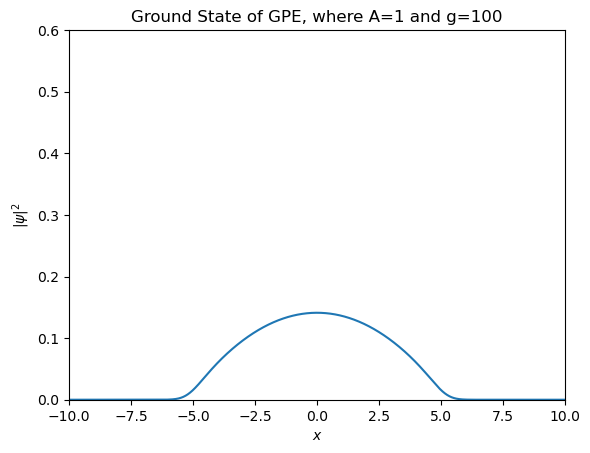

In [199]:
plt.plot(x, np.abs(psi)**2) 
plt.xlim(-10, 10)
plt.ylabel (r'$|\psi|^2$')
plt.xlabel (r'$x$')
plt.ylim (0, 0.6) 
plt.title(f"Ground State of GPE, where A={A} and g={g}")

In [124]:
dx = 0.001
x = np.arange(-10, 10, dx)

def groundstateGPE (A, g) : 
    dx = 0.001; #space steps 
    x = np.arange(-10, 10, dx) # space array
    
    dt = 1e-3 #time step
    no_tsteps = int(50/dt) 
    
    #A=1 # Harmonic trap strength
    #g=10 # interaction strength
    
    psi = np.zeros(len(x), dtype=complex)
    
    gamma = (1+1j) # imaginary time (if gamma = 0 -> real time ) 
    c0 = dt / (1j - gamma) # -dt 
    
    wavenumbers = 2*np.pi*fftfreq(len(x), d=dx) # wavenumbers 'grid'
    
    V = 0.5*A*x**2 # trapping potential 
    kinetic = np.exp(c0 * 0.5 * wavenumbers**2) #kinetic
    
    def normalize(psi) : 
        return psi/np.sqrt(np.sum(np.abs(psi) ** 2) * dx)
                
    def evolution(psi): 
        psi_density = np.abs(psi)**2
        psi = ifft(fft(psi)*kinetic) # kinetic evolution (USing FFT) 
        psi *= np.exp(c0*(V+g*psi_density)) # Trapping Potential + Interaction
    
        psi = normalize(psi)
        return psi
    
    def energy(psi):
        dpsi = (np.roll(psi, -1) - np.roll(psi, 1)) / (2 *dx)                 # spectral derivative
        #dpsi = ifft(1j * wavenumbers * fft(psi))
        E_kinetic = 0.5 * np.sum(np.abs(dpsi)**2) * dx
        E_potential = np.sum(V * np.abs(psi)**2) * dx
        E_interaction = 0.5 * g * np.sum(np.abs(psi)**4) * dx
        return E_kinetic, E_potential , E_interaction
    
    psi=(np.exp(-0.5 * x**2) / np.pi**0.25).astype(complex) #initial state (From Gaussian Shape)
    psi = normalize(psi)
    
    # energy convergence 
    E_prev = sum(energy(psi) )
    #print(f"Initial Energy E_0 = {E_prev:.10f}")
    
    
    for i in range(no_tsteps): 
        psi = evolution(psi)
        E_kinetic, E_potential , E_interaction = energy(psi)
        E_curr = E_kinetic+ E_potential + E_interaction
    
        E_diff = abs(E_curr - E_prev) 
    
        #if i % 1000 == 0 or E_diff < 1e-13 : 
           # print(f"step {i} = {E_curr:.13f}") 
           # print(f"Potential Energy : {E_potential:.13f}, Kinetic Energy : {E_kinetic:.13f}, Interaction : {E_interaction:.13f}\n")
    
        if E_diff < 1e-13 : 
            print("Done!") 
            break
            #print(f"\nConvergence achieved at step {i}!")
            #print(f"Ground State Energy E_g  = {E_curr:.13f}")
            
    
        E_prev = E_curr

    return np.abs(psi)**2

In [108]:
# (A, g) 
psi_g0 = groundstateGPE(1,0) 
psi_g10 = groundstateGPE (1, 10)
psi_g100 = groundstateGPE (1, 100)

psi_A0 = groundstateGPE (0, 0)
psi_A05 = groundstateGPE (0.5, 0)
psi_A1 = groundstateGPE (1, 0)

Done!
Done!


<function matplotlib.pyplot.show(close=None, block=None)>

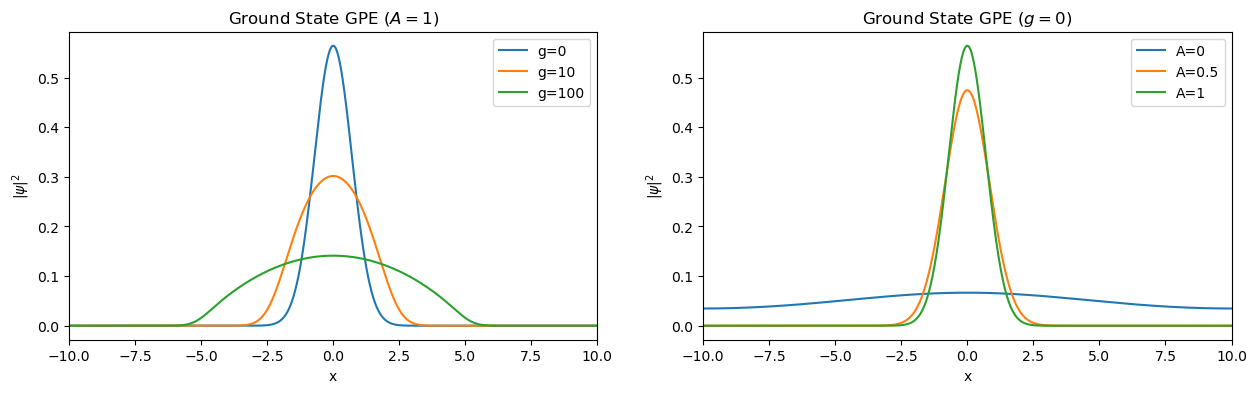

In [109]:
 # space array

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))

ax1.plot(x, psi_g0,label = "g=0")
ax1.plot(x, psi_g10 ,label = "g=10")
ax1.plot(x, psi_g100 ,label = "g=100")

ax1.set_xlim(-10,10)
ax1.legend()

ax2.plot(x, psi_A0,label = "A=0")
ax2.plot(x, psi_A05 ,label = "A=0.5")
ax2.plot(x, psi_A1 ,label = "A=1")

ax2.set_xlim(-10,10)
ax2.legend()

ax1.set_title("Ground State GPE " r"$(A=1)$")
ax2.set_title("Ground State GPE " r"$(g=0)$")

ax1.set(ylabel=r'$|\psi|^2$', xlabel=r'x')
ax2.set(ylabel=r'$|\psi|^2$', xlabel=r'x')

plt.show

In [182]:
k = np.fft.fftshift(wavenumbers)                       # reorder k: negative -> positive

In [183]:
def momentumDist (psi, x):
    dk = 2 * np.pi / (len(x) * dx)                         # spacing in k
    
    phi = np.fft.fftshift(fft(np.abs(psi)**2)) * dx / np.sqrt(2*np.pi)  # momentum-space wavefunction
    n_k = np.abs(phi)**2                                   # momentum distribution 
    return n_k

### Don't RUN

In [188]:
n_k_g0 = momentumDist(psi, k) 

In [192]:
n_k_g10 = momentumDist(psi, k) 

In [200]:
n_k_g100 = momentumDist(psi, k) 

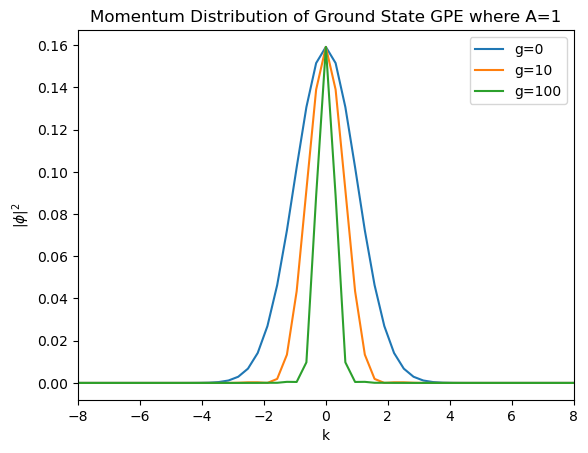

In [201]:
plt.plot(k, n_k_g0, label = "g=0")
plt.plot(k, n_k_g10, label = "g=10")
plt.plot(k, n_k_g100, label = "g=100")
plt.ylabel(r'$|\phi|^2$') 
plt.xlabel('k')
plt.title(f"Momentum Distribution of Ground State GPE where A={A}")
plt.xlim(-8,8)
plt.legend()

In [203]:
n_k_A0 = momentumDist(psi, k) 

In [223]:
n_k_A05 = momentumDist(psi, k) 

In [220]:
n_k_A1= momentumDist(psi, k) 

ValueError: x and y must have same first dimension, but have shapes (2000,) and (20000,)

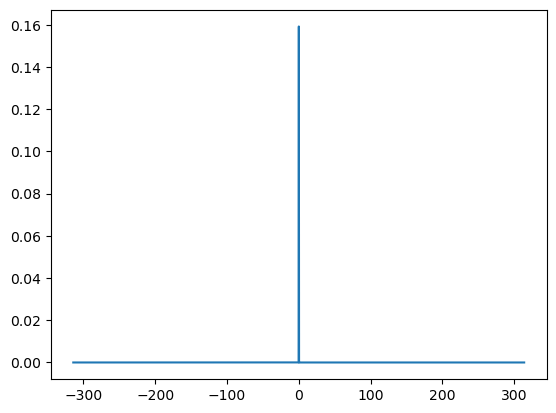

In [224]:
plt.plot(k, n_k_A0, label = "A=0")
plt.plot(k, n_k_A05, label = "A=0.5")
plt.plot(k, n_k_A1, '--', label = "A=1")
plt.ylabel(r'$|\phi|^2$') 
plt.xlabel('k')
plt.title(f"Momentum Distribution of Ground State GPE where g={g}")
plt.xlim(-8,8)
plt.legend()